## Лабораторная работа № 1
### Часть 2. Разведочный анализ Delivery ETA

Объект наблюдения — потенциальный заказ в сервисе онлайн-доставки продуктов. Целевая переменная `delivery_eta_minutes` — время прибытия курьера в минутах.

Выполним пункты задания: определим типы признаков, исследуем и устраним пропуски и выбросы, рассчитаем статистики, построим распределения важных признаков и корреляции.

Данные читаются из таблицы Iceberg, созданной первой частью. Исходный файл загружается в HDFS **отдельно в терминале сервера** командой `hdfs dfs -copyFromLocal`, описанной в первой части. Этот ноутбук ничего не копирует.

Ячейки выполняются сверху вниз на сервере с Spark 3.5 / Scala 2.12 и YARN. Расчёты выполняются на всей таблице; для графиков на драйвер передаются только ограниченные сводки. Код намеренно использует отдельные фильтры и подсчёты, поэтому на большом датасете потребуется время.


### 1. Подключение библиотек и Spark
Используем функции PySpark для расчётов и Matplotlib для графиков. Обучение моделей в эту часть работы не входит.


In [1]:
import os  # Имя пользователя сервера.
import math  # Проверка, что результат корреляции — конечное число.
from pyspark import SparkConf  # Настройки Spark.
from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as F  # Функции для столбцов.
import matplotlib.pyplot as plt  # Построение графиков.


### Выбор параметров анализа

В Delivery ETA 221 числовой признак, 1 бинарный признак и 3 категориальных признака. Вывести подробные графики для всех числовых столбцов и всех категорий на одном этапе неудобно. Поэтому зададим отдельно правило обработки пропусков и ограничения объёма визуализации.

**`missing_threshold = 0.50` — правило исключения числового признака.**

Для каждого `num_*` рассчитываем долю пропусков: число NULL, делённое на число строк после очистки целевой переменной. Если доля **больше 50%**, удаляем столбец. При доле ровно 50% столбец сохраняется.

Порог выбран так, чтобы в сохранённом столбце число наблюдаемых значений было не меньше числа восстанавливаемых. Иначе большая часть столбца после заполнения могла бы состоять из одной искусственно подставленной медианы. Для обезличенных признаков у нас нет предметного основания восстанавливать столь значительную часть данных.

Это объясняет принятое правило, но **не доказывает оптимальность порога 50%**. Даже сильно разреженный признак может содержать полезную информацию. Поэтому перед удалением показываем фактическую долю пропусков каждого столбца, а в итогах указываем потери признаков. Для этой работы порог служит явным упрощением очистки.

**`top_features_count = 5` — число числовых признаков для подробных рисунков.**

Корреляцию с целью рассчитываем для **всех сохранённых числовых признаков**, затем выбираем до пяти с наибольшим абсолютным коэффициентом Пирсона. Используем модуль, чтобы учитывать как положительную, так и отрицательную связь.

Пять признаков дают 10 отдельных рисунков распределений — по гистограмме и ящику с усами на каждый. Вместе с целевой переменной получается корреляционная матрица размером не более 6 × 6, значения которой можно прочитать без перегруженного изображения.

Число 5 ограничивает подробный показ, а **не количество сохраняемых столбцов**. Оно не означает, что остальные признаки бесполезны, и не является результатом подбора качества модели.

**`top_categories_count = 15` — число категорий на одном рисунке.**

У части `cat_*` много различных кодов. Выбираем до 15 самых частых категорий, чтобы подписи оставались читаемыми, а частоты и среднее время прибытия можно было сравнить на паре графиков. Если категорий меньше 15, показываем все.

Это ограничение оформления: остальные категории и их строки остаются в данных и участвуют в общих расчётах. Показанные категории не обязательно охватывают большую часть заказов — это зависит от распределения. По такому графику нельзя делать вывод о неотображённом хвосте категорий.

Для распределения по часам используется отдельный предел **24**, поскольку в сутках 24 часа: там показываем все представленные часы в календарном порядке.

Таким образом, только порог пропусков меняет состав сохраняемых признаков. Параметры 5 и 15 ограничивают подробность рисунков; они не отбирают строки датасета.


In [2]:
# База и входная таблица должны совпадать с первой частью.
user_name = os.getenv("USER")
database_name = "delivery_eta_database"
source_table = f"spark_catalog.{database_name}.sobd_lab1_delivery_eta"
processed_table = f"spark_catalog.{database_name}.sobd_lab1_delivery_eta_processed"
target_col = "delivery_eta_minutes"
timestamp_col = "timestamp"

# Это выбранные правила анализа, а не свойства предметной области.
missing_threshold = 0.50  # Удаляем числовые признаки, где пропущено больше половины значений.
top_features_count = 5  # Для подробных графиков выбираем до пяти числовых признаков.
top_categories_count = 15  # Показываем до 15 наиболее частых категорий.


In [3]:
# Объявляем функцию без аргументов. -> SparkConf — подсказка о типе возвращаемого результата.
def create_spark_configuration() -> SparkConf:
    """Настройки Spark 3.5 и Iceberg для учебного кластера."""
    # Создаём пустой набор настроек и ниже заполняем его.
    conf = SparkConf()
    # Имя приложения, по которому его можно найти в Spark UI и YARN.
    conf.setAppName("lab 1 Delivery ETA - exploratory analysis")
    # YARN распределяет ресурсы Hadoop-кластера; вычисления будут выполняться на кластере.
    conf.setMaster("yarn")
    # Режим client: драйвер управляет работой из процесса ноутбука, исполнители выполняют задачи на кластере.
    conf.set("spark.submit.deployMode", "client")
    # Каждому исполнителю запрашиваем 12 ГБ оперативной памяти.
    conf.set("spark.executor.memory", "12g")
    # Каждому исполнителю выделяем 8 процессорных ядер.
    conf.set("spark.executor.cores", "8")
    # Запрашиваем 2 исполнителя: вместе это 16 ядер; фактическое выделение зависит от кластера.
    conf.set("spark.executor.instances", "2")
    # Запрашиваем 4 ГБ для драйвера. В client-режиме лимит памяти JVM задают до её запуска.
    conf.set("spark.driver.memory", "4g") # память драйвера: 4 ГБ; он принимает результаты collect() и toPandas(), поэтому не стоит просить у него слишком много данных
    conf.set("spark.driver.cores", "2")
    # Подключаем Iceberg 1.6.0 для Spark 3.5 и Scala 2.12: библиотека нужна для чтения и записи таблиц.
    conf.set("spark.jars.packages",
             "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    # Включаем расширения Spark SQL для работы с Iceberg.
    conf.set("spark.sql.extensions",
             "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    # Назначаем каталогу spark_catalog реализацию Iceberg, которая знает формат этих таблиц.
    conf.set("spark.sql.catalog.spark_catalog",
             "org.apache.iceberg.spark.SparkCatalog")
    # Метаданные таблиц будут храниться в файловой системе, без отдельного сервера каталога.
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    # Папка в HDFS для файлов и метаданных наших таблиц; имя пользователя подставится автоматически.
    conf.set("spark.sql.catalog.spark_catalog.warehouse",
             f"hdfs:///user/{user_name}/warehouse")
    # Указываем класс, через который Iceberg будет читать и записывать файлы Hadoop/HDFS.
    conf.set("spark.sql.catalog.spark_catalog.io-impl",
             "org.apache.iceberg.hadoop.HadoopFileIO")
    # Возвращаем готовые настройки туда, откуда была вызвана функция.
    return conf

# Вызываем функцию: теперь переменная conf хранит все перечисленные настройки.
conf = create_spark_configuration()

# Создаём сессию с теми же настройками каталога Iceberg, что в первой части.
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark


:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-7ca17c83-c9fb-4d3d-a0b2-68a61104b162;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 619ms :: artifacts dl 26ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

### 2. Типы признаков и исходные данные
Числовые `num_*` — количественные признаки. `bin_*` принимают два состояния. `cat_*` — коды категорий, для которых среднее арифметическое не имеет предметного смысла. Временную метку используем для анализа периода наблюдений.


In [4]:
# Читаем результат первой части.
df = spark.table(source_table)
num_cols = []
bin_cols = []
cat_cols = []
for column in df.columns:
    if column.startswith("num_"):
        num_cols.append(column)
    elif column.startswith("bin_"):
        bin_cols.append(column)
    elif column.startswith("cat_"):
        cat_cols.append(column)

df.printSchema()
preview_cols = num_cols[:5] + bin_cols + cat_cols + [timestamp_col, target_col]
df.select(preview_cols).show(5, truncate=30)
initial_rows = df.count()
print(f"Исходных строк: {initial_rows}")
print(f"Числовых признаков: {len(num_cols)}")
print(f"Бинарных признаков: {len(bin_cols)}")
print(f"Категориальных признаков: {len(cat_cols)}")


root
 |-- num_0: float (nullable = true)
 |-- num_1: float (nullable = true)
 |-- num_2: float (nullable = true)
 |-- num_3: float (nullable = true)
 |-- num_4: float (nullable = true)
 |-- num_5: float (nullable = true)
 |-- num_6: float (nullable = true)
 |-- num_7: float (nullable = true)
 |-- num_8: float (nullable = true)
 |-- num_9: float (nullable = true)
 |-- num_10: float (nullable = true)
 |-- num_11: float (nullable = true)
 |-- num_12: float (nullable = true)
 |-- num_13: float (nullable = true)
 |-- num_14: float (nullable = true)
 |-- num_15: float (nullable = true)
 |-- num_16: float (nullable = true)
 |-- num_17: float (nullable = true)
 |-- num_18: float (nullable = true)
 |-- num_19: float (nullable = true)
 |-- num_20: float (nullable = true)
 |-- num_21: float (nullable = true)
 |-- num_22: float (nullable = true)
 |-- num_23: float (nullable = true)
 |-- num_24: float (nullable = true)
 |-- num_25: float (nullable = true)
 |-- num_26: float (nullable = true)
 |-- n

+------------+----------+-----------+----------+------------+-----+-----+-----+-----+-------------------+--------------------+
|       num_0|     num_1|      num_2|     num_3|       num_4|bin_0|cat_0|cat_1|cat_2|          timestamp|delivery_eta_minutes|
+------------+----------+-----------+----------+------------+-----+-----+-----+-----+-------------------+--------------------+
|-0.005018293|0.34681705| 0.22005822|-1.1971933|-0.062015414|  0.0|  240|  249|  249|2023-10-22 05:33:58|                2.75|
|  -1.4215561|-0.6611619|-0.32491526| 0.3255765|  -1.4291298|  1.0|  103|  131|  131|2023-12-25 09:05:20|           0.8666667|
|  0.13148026|0.66741896|  0.6356186|-1.2612822|  0.15100867|  1.0|  303|  316|  316|2023-11-13 14:02:21|                 9.8|
|  0.73812836|-0.8808932| -0.9830647|0.47100437|   0.7496954|  1.0|  476|  508|  508|2023-12-21 18:08:18|                12.9|
| -0.47802472|0.58399165|  0.7529975|-0.4696031| -0.50353813|  0.0|  191|  197|  197|2023-11-18 10:49:51|      

Исходных строк: 17044043
Числовых признаков: 221
Бинарных признаков: 1
Категориальных признаков: 3


### 3. Исходные пропуски
Первая часть уже заменила обнаруженные NaN и бесконечности на NULL. Теперь подсчитаем пропуски до очистки. Все столбцы считаются одним проходом, а не отдельным `count()` на каждый признак.


In [5]:
def missing_summary(data, row_count):
    # Один agg на все столбцы: таблица читается один раз.
    aggregates = []
    for column in data.columns:
        aggregates.append(F.sum(F.col(column).isNull().cast("long")).alias(column))
    counts = data.agg(*aggregates).first().asDict()

    for column in data.columns:
        missing_count = counts[column]
        if missing_count > 0:
            share = 0.0
            if row_count > 0:
                share = missing_count / row_count
            print(f"{column}: {missing_count} пропусков ({share:.2%})")
    return counts

missing_before = missing_summary(df, initial_rows)


26/10/28 19:52:41 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


num_10: 11238 пропусков (0.07%)
num_11: 11238 пропусков (0.07%)
num_76: 9517563 пропусков (55.84%)
num_77: 9517563 пропусков (55.84%)
num_78: 9517563 пропусков (55.84%)
num_79: 9517563 пропусков (55.84%)
num_80: 9517563 пропусков (55.84%)
num_81: 10129523 пропусков (59.43%)
num_82: 10129523 пропусков (59.43%)
num_83: 10129523 пропусков (59.43%)
num_84: 10129523 пропусков (59.43%)
num_85: 10129523 пропусков (59.43%)
num_86: 9580071 пропусков (56.21%)
num_87: 9580071 пропусков (56.21%)
num_88: 9580071 пропусков (56.21%)
num_89: 9580071 пропусков (56.21%)
num_90: 9580071 пропусков (56.21%)
num_91: 9517563 пропусков (55.84%)
num_92: 9517563 пропусков (55.84%)
num_93: 9517563 пропусков (55.84%)
num_94: 9517563 пропусков (55.84%)
num_95: 9517563 пропусков (55.84%)
num_96: 9517563 пропусков (55.84%)
num_97: 9517563 пропусков (55.84%)
num_98: 9517563 пропусков (55.84%)
num_99: 9517563 пропусков (55.84%)
num_100: 9517563 пропусков (55.84%)
num_101: 9517563 пропусков (55.84%)
num_102: 9517563 пр

### 4. Проверка целевой переменной и времени

Отрицательное время прибытия не имеет физического смысла. Покажем такие строки и их число, затем удалим их. Также удалим строки с отсутствующей целью: заполнять фактическое время прибытия средним или медианой означало бы придумывать ответ.

Для временного анализа нужны наблюдения с известным `timestamp`, поэтому строки без него исключаем с отдельным подсчётом. Нулевое время пока сохраняем: из доступного описания нельзя установить, обязательно ли это ошибка.


In [6]:
# Сначала показываем обнаруженную проблему.
negative_rows = df.filter(F.col(target_col) < 0)
negative_rows.select(timestamp_col, target_col).show(10, truncate=False)
negative_count = negative_rows.count()
print(f"Отрицательных длительностей: {negative_count}")

# Каждое правило выполняем отдельно, чтобы видеть причины удаления строк.
missing_target_count = df.filter(F.col(target_col).isNull()).count()
df = df.filter(F.col(target_col).isNotNull())
df = df.filter(F.col(target_col) >= 0)

missing_time_count = df.filter(F.col(timestamp_col).isNull()).count()
df = df.filter(F.col(timestamp_col).isNotNull())

valid_rows = df.count()
print(f"Удалено строк без цели: {missing_target_count}")
print(f"Удалено строк без временной метки после проверки цели: {missing_time_count}")
print(f"Осталось строк: {valid_rows}")


+---------+--------------------+
|timestamp|delivery_eta_minutes|
+---------+--------------------+
+---------+--------------------+



Отрицательных длительностей: 0


Удалено строк без цели: 0
Удалено строк без временной метки после проверки цели: 0
Осталось строк: 17044043


### 5. Статистика и графики времени прибытия до удаления выбросов
Рассчитаем минимум, максимум, среднее, стандартное отклонение, квартиль Q1, медиану, квартиль Q3 и 95-й процентиль. Квантили вычисляются приближённо: `0.001` — ошибка по рангу, а не в минутах. Пустой столбец пропускаем, чтобы не строить бессодержательный график.


In [7]:
def column_statistics(data, column):
    # describe() выводит количество непустых значений, среднее, отклонение, минимум и максимум.
    data.select(column).describe().show()

    non_empty = data.filter(F.col(column).isNotNull())
    quantiles = non_empty.approxQuantile(column, [0.25, 0.50, 0.75, 0.95], 0.001)
    statistics = {}
    if len(quantiles) == 4:
        statistics["q1"] = quantiles[0]
        statistics["median"] = quantiles[1]
        statistics["q3"] = quantiles[2]
        statistics["p95"] = quantiles[3]
        print(f"{column}: Q1={quantiles[0]:.3f}, медиана={quantiles[1]:.3f}")
        print(f"{column}: Q3={quantiles[2]:.3f}, P95={quantiles[3]:.3f}")
    return statistics

target_statistics = column_statistics(df, target_col)


+-------+--------------------+
|summary|delivery_eta_minutes|
+-------+--------------------+
|  count|            17044043|
|   mean|   7.532908285737899|
| stddev|   6.239175628436336|
|    min|                 0.0|
|    max|           170.51666|
+-------+--------------------+



delivery_eta_minutes: Q1=3.350, медиана=5.433
delivery_eta_minutes: Q3=9.733, P95=20.383


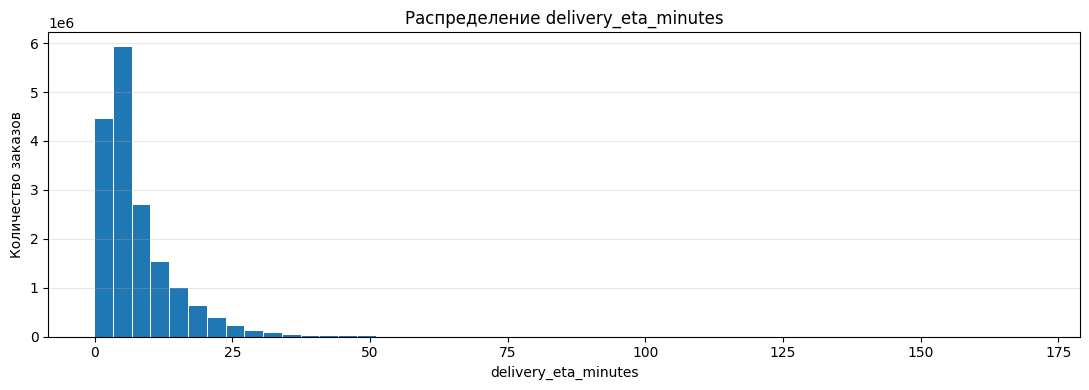

In [8]:
def plot_histogram(data, column, bins=50):
    # Выбираем непустые значения одного столбца.
    values = data.filter(F.col(column).isNotNull())
    minimum = values.select(F.min(column)).first()[0]
    maximum = values.select(F.max(column)).first()[0]
    if minimum is None:
        return

    fig, ax = plt.subplots(figsize=(11, 4))
    if minimum == maximum:
        # Для постоянного признака нет диапазона: показываем один столбик.
        ax.bar([minimum], [values.count()])
    else:
        width = (maximum - minimum) / bins
        # Каждой строке назначаем номер интервала.
        values = values.withColumn("histogram_bucket",
                                   F.floor((F.col(column) - minimum) / width))
        # Максимальное значение помещаем в последний интервал.
        values = values.withColumn(
            "histogram_bucket",
            F.when(F.col("histogram_bucket") >= bins, bins - 1)
             .otherwise(F.col("histogram_bucket"))
        )
        frequencies = values.groupBy("histogram_bucket").count()
        frequencies = frequencies.orderBy("histogram_bucket")
        # Передаём на драйвер максимум bins строк, а не весь датасет.
        rows = frequencies.collect()
        centers = []
        counts = []
        for row in rows:
            center = minimum + (row["histogram_bucket"] + 0.5) * width
            centers.append(center)
            counts.append(row["count"])
        ax.bar(centers, counts, width=width * 0.95)

    ax.set_xlabel(column)
    ax.set_ylabel("Количество заказов")
    ax.set_title(f"Распределение {column}")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_histogram(df, target_col)


Ящик с усами строим по статистикам всей таблицы. Усы заканчиваются на фактических значениях внутри границ Q1 − 1,5×IQR и Q3 + 1,5×IQR. Для отображения точек за границами берём не более 100 наблюдений; это иллюстрация, а не случайная выборка всех выбросов.


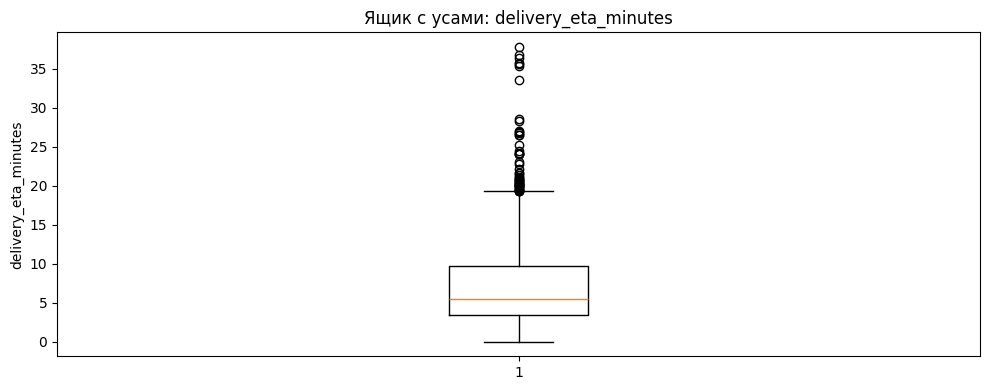

In [9]:
def plot_boxplot(data, column, statistics):
    if len(statistics) == 0:
        return
    q1 = statistics["q1"]
    q3 = statistics["q3"]
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    inside = data.filter(F.col(column) >= lower)
    inside = inside.filter(F.col(column) <= upper)
    whisker_min = inside.select(F.min(column)).first()[0]
    whisker_max = inside.select(F.max(column)).first()[0]
    if whisker_min is None:
        return

    # Для рисунка берём ограниченное число точек с обеих сторон.
    lower_rows = data.filter(F.col(column) < lower).select(column).limit(50).collect()
    upper_rows = data.filter(F.col(column) > upper).select(column).limit(50).collect()
    points = []
    for row in lower_rows:
        points.append(row[column])
    for row in upper_rows:
        points.append(row[column])

    box = {
        "q1": q1,
        "med": statistics["median"],
        "q3": q3,
        "whislo": whisker_min,
        "whishi": whisker_max,
        "fliers": points,
    }
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bxp([box])
    ax.set_ylabel(column)
    ax.set_title(f"Ящик с усами: {column}")
    plt.tight_layout()
    plt.show()

plot_boxplot(df, target_col, target_statistics)


### 6. Выявление и устранение выбросов

Для задания принимаем **статистическое правило IQR** для времени прибытия: исключаем строки вне интервала Q1 − 1,5×IQR … Q3 + 1,5×IQR. Нижняя граница не может быть меньше нуля. Сначала считаем, сколько строк затронет правило, затем применяем фильтр и повторяем статистики и распределение.

Долгое ожидание курьера может быть реальным. Поэтому это выбранное правило ограничения хвостов распределения, а не утверждение, что все исключённые заказы ошибочны. Потери данных обязательно отражаем в выводах. При IQR = 0 фильтрацию не выполняем: одинаковые квартильные значения не дают обоснованного диапазона.

К обезличенным `num_*` такое правило автоматически не применяем: их единицы и смысл неизвестны. Категориальные коды не проверяем на выбросы как непрерывные числа.


Границы фильтрации: 0.000 — 19.308 минут


Строк за границами: 1023764 (6.01%)


После обработки выбросов: 16020279 строк


+-------+--------------------+
|summary|delivery_eta_minutes|
+-------+--------------------+
|  count|            16020279|
|   mean|   6.411267122844159|
| stddev|   4.286287633875724|
|    min|                 0.0|
|    max|                19.3|
+-------+--------------------+



delivery_eta_minutes: Q1=3.233, медиана=5.117
delivery_eta_minutes: Q3=8.600, P95=15.617


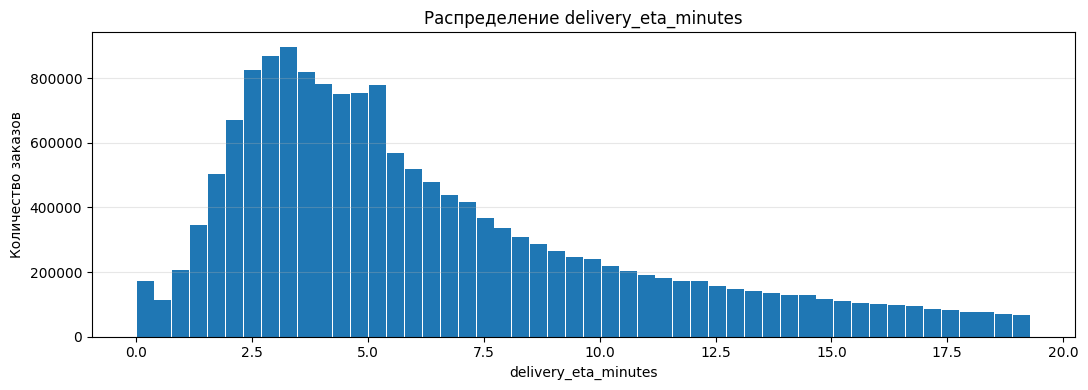

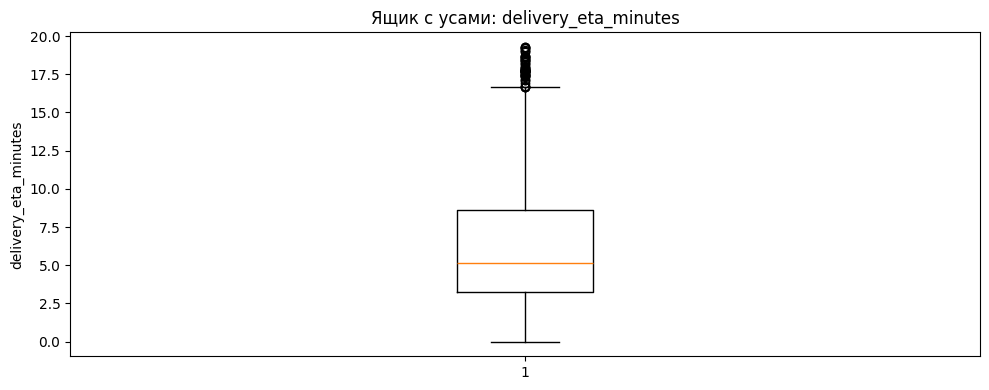

In [10]:
rows_after_outliers = valid_rows
outlier_count = 0

if len(target_statistics) > 0:
    q1 = target_statistics["q1"]
    q3 = target_statistics["q3"]
    iqr = q3 - q1

    if iqr > 0:
        lower_bound = q1 - 1.5 * iqr
        if lower_bound < 0:
            lower_bound = 0.0
        upper_bound = q3 + 1.5 * iqr
        print(f"Границы фильтрации: {lower_bound:.3f} — {upper_bound:.3f} минут")

        lower_outliers = df.filter(F.col(target_col) < lower_bound)
        upper_outliers = df.filter(F.col(target_col) > upper_bound)
        outlier_count = lower_outliers.count() + upper_outliers.count()
        print(f"Строк за границами: {outlier_count} ({outlier_count / valid_rows:.2%})")

        df = df.filter(F.col(target_col) >= lower_bound)
        df = df.filter(F.col(target_col) <= upper_bound)
        rows_after_outliers = df.count()

# Повторные расчёты показывают результат выбранной очистки.
print(f"После обработки выбросов: {rows_after_outliers} строк")
target_statistics_after = column_statistics(df, target_col)
plot_histogram(df, target_col)
plot_boxplot(df, target_col, target_statistics_after)


### 7. Пропуски в числовых признаках

После удаления строк повторно считаем доли пропусков. В рамках этой работы исключаем `num_*` с долей пропусков **более 50%**: большую часть такого столбца пришлось бы восстанавливать искусственно. Это выбранное упрощение, а не доказательство бесполезности признака.

В оставшихся числовых столбцах пропуски заполняем **медианой** наблюдаемых значений. Она менее чувствительна к длинным хвостам, чем среднее. Число строк при заполнении не меняется; распределение около медианы может получить дополнительный пик.

Цель и время заказа не заполняем. Их пропуски обработаны отдельно. Эти расчёты предназначены для EDA; при дальнейшем обучении медианы и отбор столбцов нужно определять только на обучающих данных.


In [11]:
missing_current = missing_summary(df, rows_after_outliers)
kept_num_cols = []
dropped_num_cols = []

for column in num_cols:
    share = missing_current[column] / rows_after_outliers
    if share > missing_threshold:
        dropped_num_cols.append(column)
        df = df.drop(column)  # Удаляем один столбец, а не строки.
        print(f"Удалён {column}: доля пропусков {share:.2%}")
    else:
        kept_num_cols.append(column)

numeric_fill_values = {}
for column in kept_num_cols:
    if missing_current[column] > 0:
        observed_values = df.filter(F.col(column).isNotNull())
        quantiles = observed_values.approxQuantile(column, [0.5], 0.001)
        if len(quantiles) > 0:
            median_value = quantiles[0]
            numeric_fill_values[column] = median_value
            df = df.fillna({column: median_value})
            print(f"{column}: заполнено {missing_current[column]} пропусков медианой {median_value:.4f}")


num_10: 10634 пропусков (0.07%)
num_11: 10634 пропусков (0.07%)
num_76: 8812691 пропусков (55.01%)
num_77: 8812691 пропусков (55.01%)
num_78: 8812691 пропусков (55.01%)
num_79: 8812691 пропусков (55.01%)
num_80: 8812691 пропусков (55.01%)
num_81: 9380645 пропусков (58.55%)
num_82: 9380645 пропусков (58.55%)
num_83: 9380645 пропусков (58.55%)
num_84: 9380645 пропусков (58.55%)
num_85: 9380645 пропусков (58.55%)
num_86: 8869768 пропусков (55.37%)
num_87: 8869768 пропусков (55.37%)
num_88: 8869768 пропусков (55.37%)
num_89: 8869768 пропусков (55.37%)
num_90: 8869768 пропусков (55.37%)
num_91: 8812691 пропусков (55.01%)
num_92: 8812691 пропусков (55.01%)
num_93: 8812691 пропусков (55.01%)
num_94: 8812691 пропусков (55.01%)
num_95: 8812691 пропусков (55.01%)
num_96: 8812691 пропусков (55.01%)
num_97: 8812691 пропусков (55.01%)
num_98: 8812691 пропусков (55.01%)
num_99: 8812691 пропусков (55.01%)
num_100: 8812691 пропусков (55.01%)
num_101: 8812691 пропусков (55.01%)
num_102: 8812691 пропуск

num_10: заполнено 10634 пропусков медианой -0.0540


num_11: заполнено 10634 пропусков медианой 0.0184


num_122: заполнено 426539 пропусков медианой 0.0716


num_123: заполнено 426508 пропусков медианой 0.0734


...

num_216: заполнено 768012 пропусков медианой 0.0618


num_217: заполнено 678381 пропусков медианой -0.0113


num_218: заполнено 713586 пропусков медианой 0.0569


num_219: заполнено 1438592 пропусков медианой -0.0051


num_220: заполнено 1150769 пропусков медианой -0.0158


### 8. Пропуски в бинарных и категориальных признаках
Для `bin_*` и `cat_*` используем моду — наиболее частое значение. Коды категорий не усредняем и не объединяем. Если столбец целиком пуст, моду вычислить нельзя — удаляем такой столбец. При одинаковой частоте выбираем меньший код, чтобы правило было определённым.


In [12]:
discrete_columns = bin_cols + cat_cols
kept_discrete_cols = []
dropped_discrete_cols = []

for column in discrete_columns:
    observed_values = df.filter(F.col(column).isNotNull())
    if observed_values.count() == 0:
        dropped_discrete_cols.append(column)
        df = df.drop(column)
        print(f"Удалён полностью пустой столбец: {column}")
    else:
        kept_discrete_cols.append(column)
        missing_count = df.filter(F.col(column).isNull()).count()
        if missing_count > 0:
            frequencies = observed_values.groupBy(column).count()
            frequencies = frequencies.orderBy(F.desc("count"), F.asc(column))
            mode_value = frequencies.first()[column]
            df = df.fillna({column: mode_value})
            print(f"{column}: заполнено {missing_count} пропусков модой {mode_value}")

# Проверяем результат заполнения на всех оставшихся столбцах.
missing_after = missing_summary(df, rows_after_outliers)
remaining_missing = 0
for column in missing_after:
    remaining_missing = remaining_missing + missing_after[column]
print(f"Пропусков после обработки: {remaining_missing}")


Пропусков после обработки: 0


### 9. Корреляции числовых признаков с целью

Для каждого оставшегося `num_*` вычислим коэффициент Пирсона с временем прибытия курьера. Он характеризует линейную связь: знак показывает направление, модуль — силу. Постоянные признаки не дают определённой корреляции. Категориальные коды сюда не включаем.

Расчёт относится к данным **после** фильтрации цели и заполнения медианой. Эти операции могут изменить связи. По величине корреляции нельзя восстановить скрытое название признака или доказать причинность.

Пять признаков с наибольшим модулем корреляции подробно покажем на графиках. Это критерий отбора для EDA, а не доказанная важность для будущей модели.


In [13]:
correlation_results = []
for column in kept_num_cols:
    # Один вызов — одна пара столбцов.
    correlation = df.stat.corr(column, target_col)
    if math.isfinite(correlation):
        # Первый элемент — модуль, чтобы учесть связи обоих направлений.
        correlation_results.append((abs(correlation), column, correlation))

# Обычная сортировка кортежей сначала сравнивает первый элемент.
correlation_results.sort(reverse=True)
important_num_cols = []
for result in correlation_results[:top_features_count]:
    column = result[1]
    correlation = result[2]
    important_num_cols.append(column)
    print(f"{column}: корреляция с целью {correlation:+.4f}")


num_10: корреляция с целью +0.5048
num_8: корреляция с целью +0.4968
num_127: корреляция с целью +0.1576
num_154: корреляция с целью +0.1458
num_144: корреляция с целью +0.1427


### 10. Статистики и распределения выбранных числовых признаков
Для выбранных признаков показываем среднее, отклонение, минимум, максимум, квартили, гистограммы и ящики с усами. Отрицательные значения `num_*` не считаем ошибкой только из-за знака: признаки стандартизованы и обезличены.


+-------+--------------------+
|summary|              num_10|
+-------+--------------------+
|  count|            16020279|
|   mean|-0.05357587207693272|
| stddev|  0.9807459627957344|
|    min|          -2.8351438|
|    max|           5.1993375|
+-------+--------------------+



num_10: Q1=-0.715, медиана=-0.054
num_10: Q3=0.606, P95=1.557


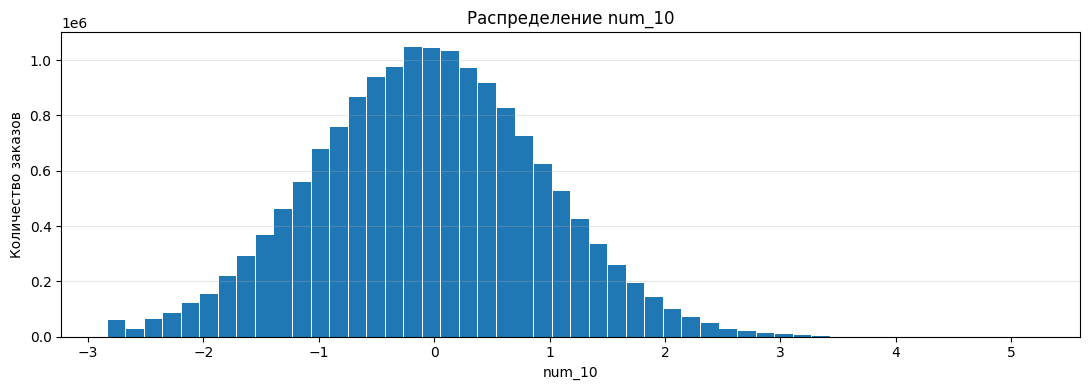

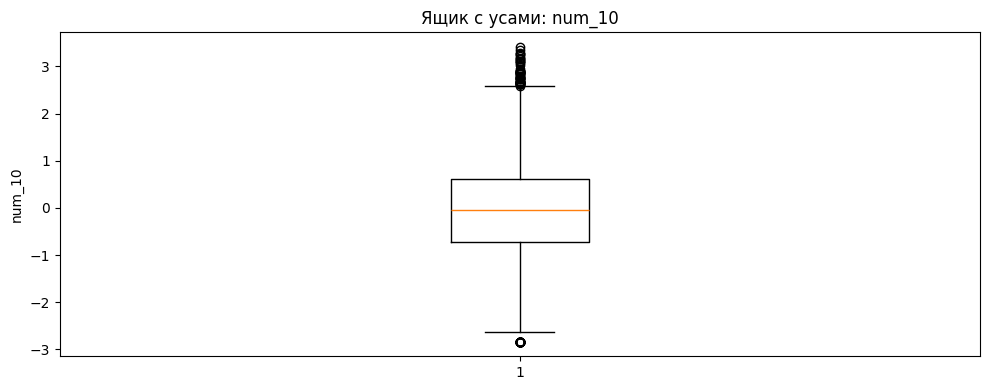

+-------+--------------------+
|summary|               num_8|
+-------+--------------------+
|  count|            16020279|
|   mean|-0.05308543086261...|
| stddev|  0.9836148425604206|
|    min|          -3.2124383|
|    max|           5.1993375|
+-------+--------------------+



num_8: Q1=-0.720, медиана=-0.054
num_8: Q3=0.610, P95=1.562


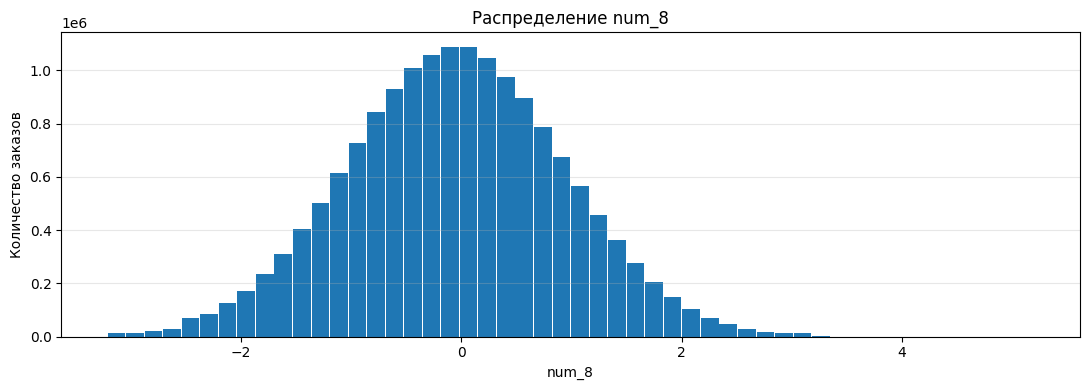

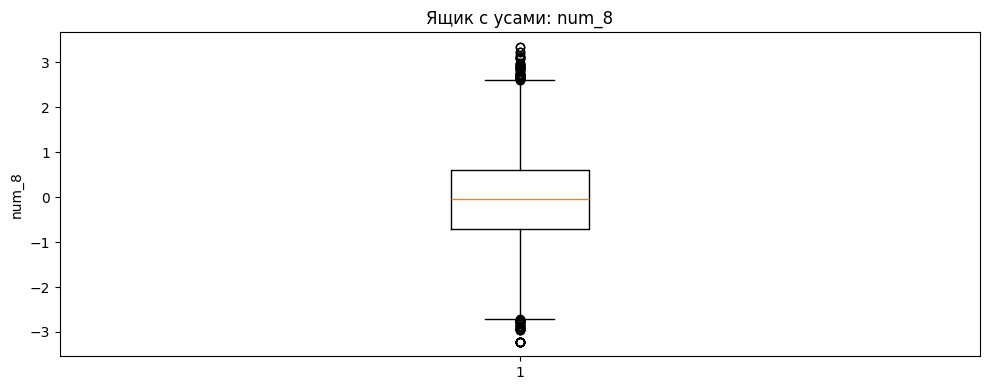

+-------+--------------------+
|summary|             num_127|
+-------+--------------------+
|  count|            16020279|
|   mean|0.005826628147204828|
| stddev|  0.9857397676659164|
|    min|          -5.1993375|
|    max|           5.1993375|
+-------+--------------------+



num_127: Q1=-0.647, медиана=-0.002
num_127: Q3=0.656, P95=1.642


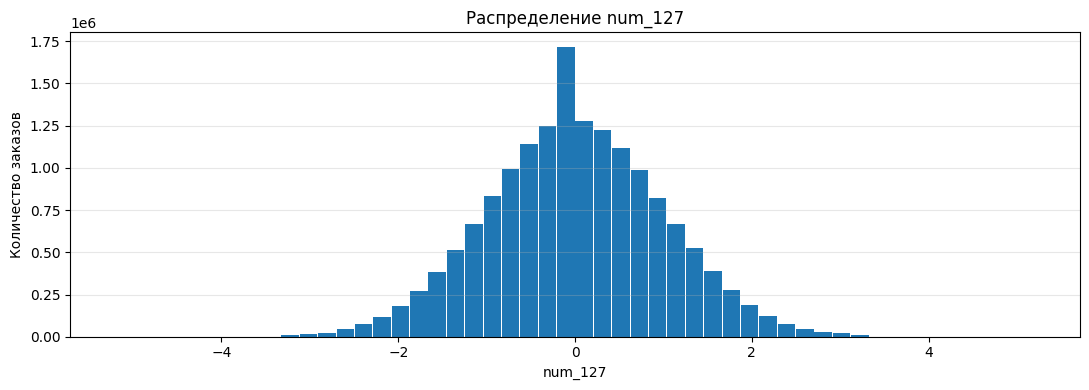

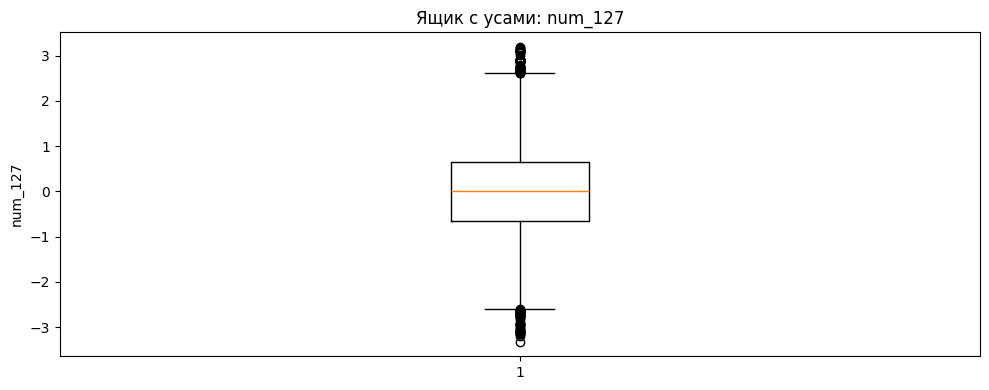

+-------+--------------------+
|summary|             num_154|
+-------+--------------------+
|  count|            16020279|
|   mean|0.001923901835074...|
| stddev|  0.9849358339716195|
|    min|          -5.1993375|
|    max|           5.1993375|
+-------+--------------------+



num_154: Q1=-0.653, медиана=-0.003
num_154: Q3=0.653, P95=1.634


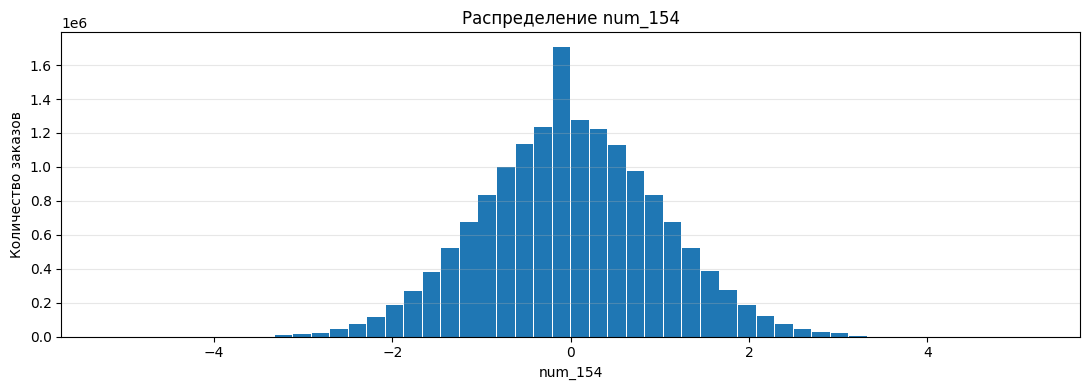

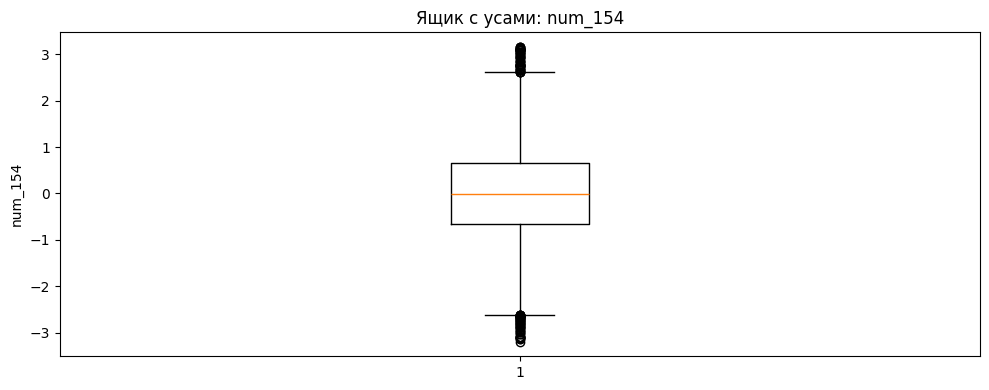

+-------+-------------------+
|summary|            num_144|
+-------+-------------------+
|  count|           16020279|
|   mean|0.14331604140031812|
| stddev| 1.0128268708167387|
|    min|         -5.1993375|
|    max|          5.1993375|
+-------+-------------------+



num_144: Q1=-0.528, медиана=0.136
num_144: Q3=0.817, P95=1.840


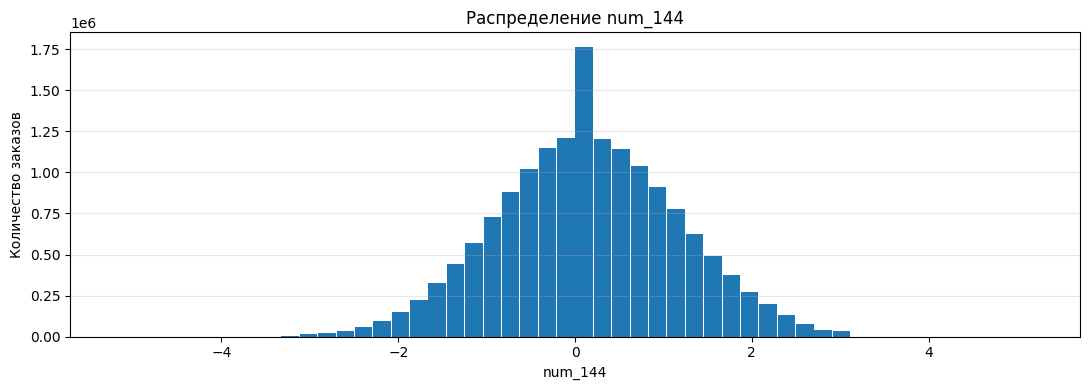

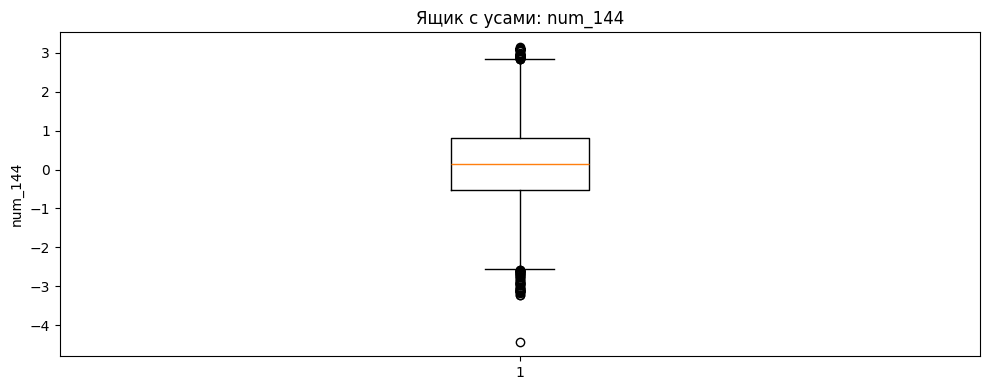

In [14]:
for column in important_num_cols:
    statistics = column_statistics(df, column)
    plot_histogram(df, column)
    plot_boxplot(df, column, statistics)


### 11. Распределения бинарных и категориальных признаков
Покажем частоты значений и среднее время прибытия в тех же группах. Для большого числа категорий рисуем только 15 наиболее частых. Размер группы важен: среднее по редкой категории менее устойчиво. Подписи категорий — коды, а не расшифрованные названия зон и типов заказов.


+-----+--------+
|bin_0|count   |
+-----+--------+
|1.0  |10926872|
|0.0  |5093407 |
+-----+--------+



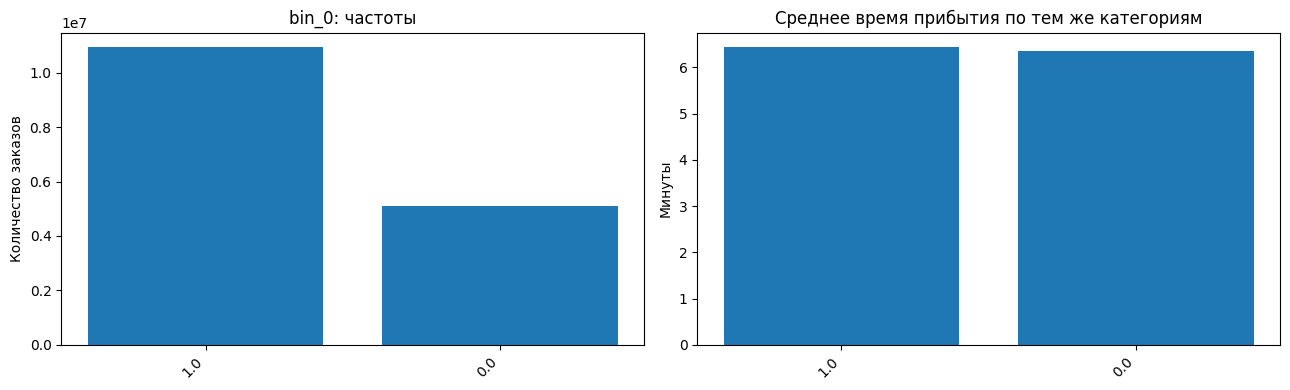

+-----+------+
|cat_0|count |
+-----+------+
|48   |155138|
|131  |130625|
|121  |125595|
|79   |121634|
|169  |109326|
|106  |108381|
|54   |105150|
|13   |91564 |
|74   |87459 |
|50   |87273 |
|92   |83840 |
|286  |76256 |
|71   |76098 |
|61   |73649 |
|160  |73284 |
+-----+------+
only showing top 15 rows



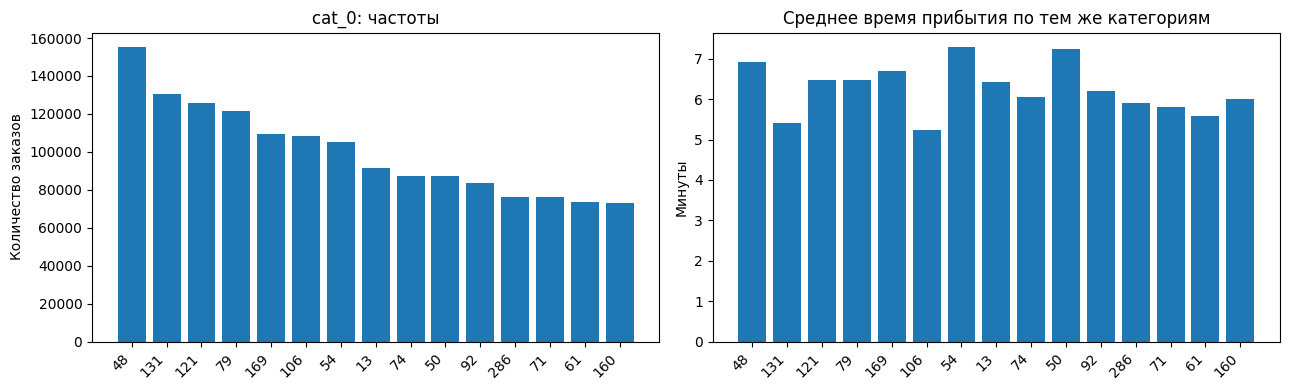

+-----+-----+
|cat_1|count|
+-----+-----+
|176  |89750|
|92   |83840|
|71   |76098|
|61   |73649|
|164  |73284|
|53   |70109|
|314  |69340|
|395  |65342|
|214  |63988|
|21   |63197|
|223  |63189|
|106  |61675|
|24   |61489|
|173  |61418|
|249  |60939|
+-----+-----+
only showing top 15 rows



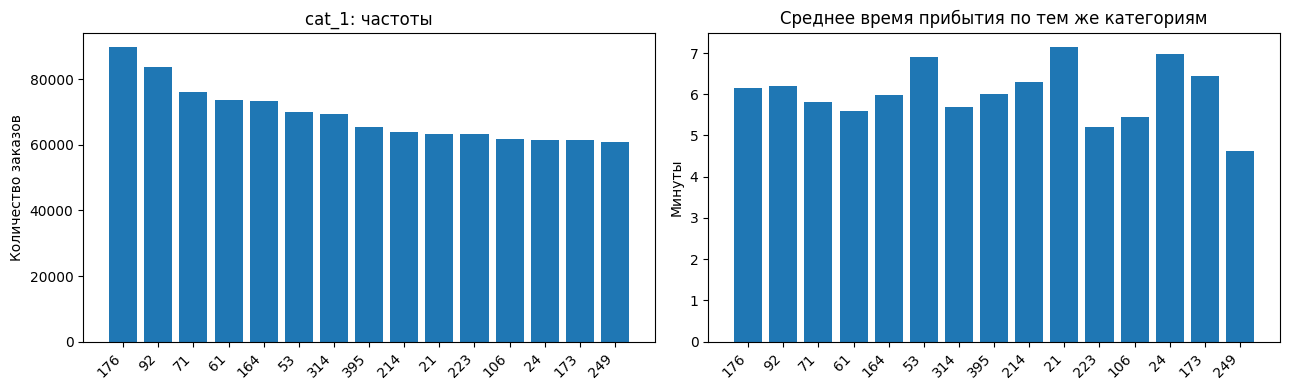

+-----+-----+
|cat_2|count|
+-----+-----+
|176  |89750|
|92   |83840|
|71   |76098|
|61   |73649|
|164  |73284|
|53   |70109|
|314  |69340|
|395  |65342|
|214  |63988|
|21   |63197|
|223  |63189|
|106  |61675|
|24   |61489|
|173  |61418|
|249  |60939|
+-----+-----+
only showing top 15 rows



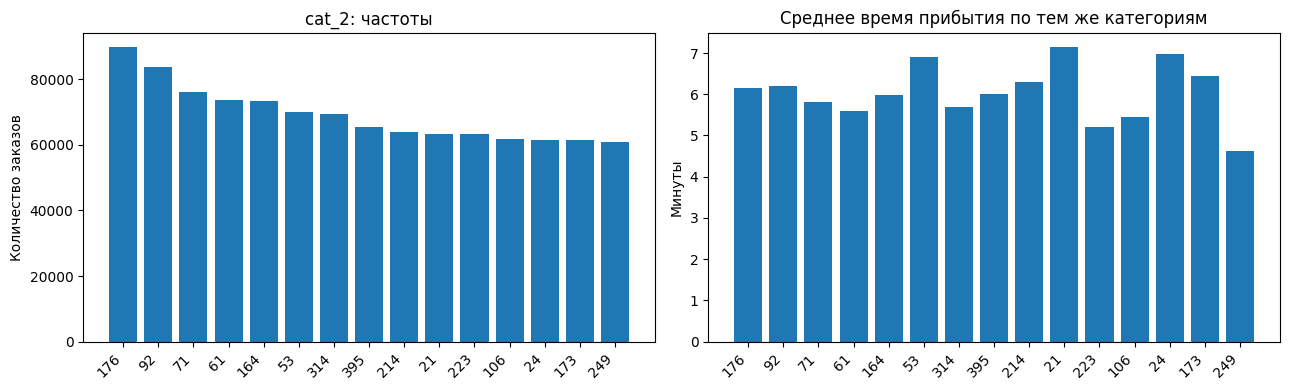

In [15]:
def plot_category(data, column, top_n=15, sort_by_value=False):
    frequencies = data.groupBy(column).count()
    # Категории обычно упорядочиваем по частоте; часы — по времени.
    if sort_by_value:
        frequencies = frequencies.orderBy(column)
    else:
        frequencies = frequencies.orderBy(F.desc("count"), F.asc(column))
    frequencies.show(top_n, truncate=False)
    rows = frequencies.limit(top_n).collect()

    labels = []
    counts = []
    mean_times = []
    for row in rows:
        category = row[column]
        labels.append(str(category))
        counts.append(row["count"])

        # Сначала отбираем категорию, затем считаем среднее по её строкам.
        category_rows = data.filter(F.col(column) == category)
        mean_time = category_rows.select(F.mean(target_col)).first()[0]
        mean_times.append(mean_time)

    if len(labels) == 0:
        return
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    positions = list(range(len(labels)))
    axes[0].bar(positions, counts)
    axes[0].set_title(f"{column}: частоты")
    axes[0].set_ylabel("Количество заказов")
    axes[1].bar(positions, mean_times)
    axes[1].set_title("Среднее время прибытия по тем же категориям")
    axes[1].set_ylabel("Минуты")
    for ax in axes:
        ax.set_xticks(positions)
        ax.set_xticklabels(labels, rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

for column in kept_discrete_cols:
    plot_category(df, column, top_categories_count)


### 12. Распределение наблюдений по времени
Временную метку используем без назначения часового пояса. Получим суточную динамику и распределение по часам. Дополнительные столбцы создаём во временной таблице для анализа; в итоговую таблицу они не добавляются.


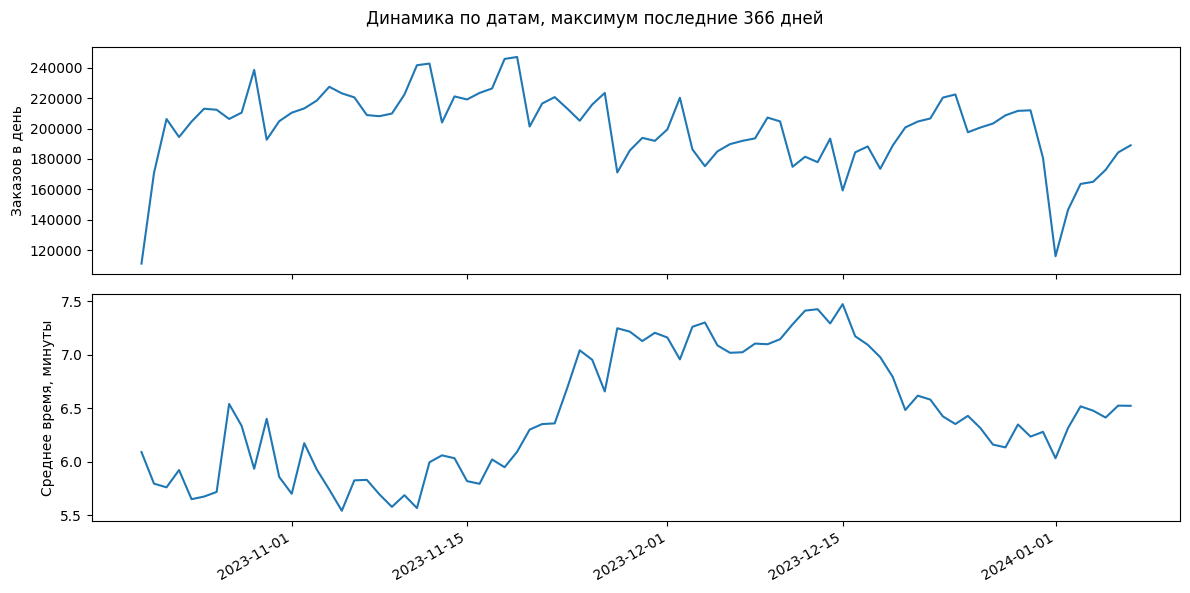

+----------------+-------+
|observation_hour|count  |
+----------------+-------+
|0               |3569   |
|1               |9084   |
|2               |18775  |
|3               |34557  |
|4               |201143 |
|5               |409111 |
|6               |693917 |
|7               |907654 |
|8               |1016267|
|9               |1078153|
|10              |1083844|
|11              |1080006|
|12              |1167921|
|13              |1215349|
|14              |1189851|
|15              |1225718|
|16              |1265436|
|17              |1216107|
|18              |1053111|
|19              |822473 |
|20              |261771 |
|21              |45491  |
|22              |20904  |
|23              |67     |
+----------------+-------+



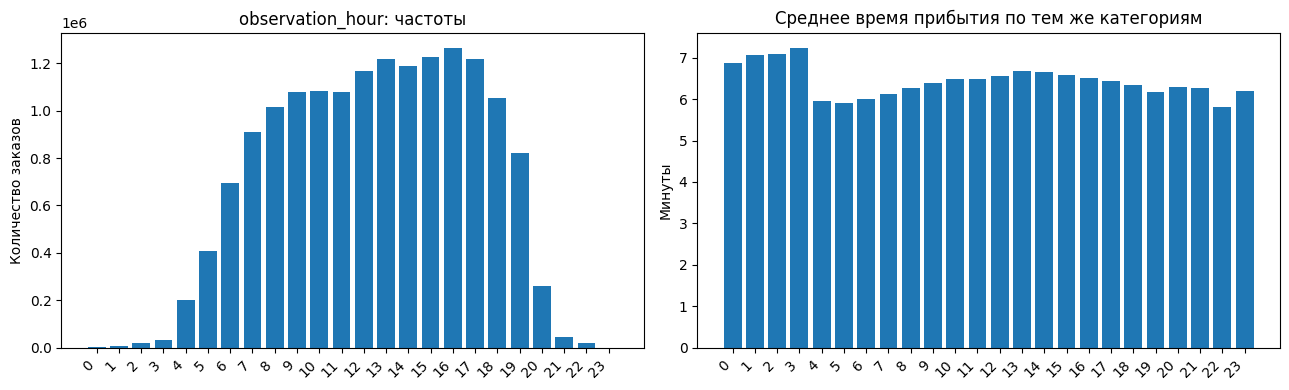

In [16]:
time_data = df.withColumn("observation_date", F.to_date(timestamp_col))
time_data = time_data.withColumn("observation_hour", F.hour(timestamp_col))

# Один проход: число заказов и среднее время по каждой дате.
daily = time_data.groupBy("observation_date").agg(
    F.count("*").alias("orders"),
    F.mean(target_col).alias("mean_eta"),
)
daily = daily.orderBy(F.desc("observation_date")).limit(366)
date_rows = daily.collect()
date_rows.reverse()  # На рисунке даты идут от ранних к поздним.

date_labels = []
daily_counts = []
daily_means = []
for row in date_rows:
    date_labels.append(row["observation_date"])
    daily_counts.append(row["orders"])
    daily_means.append(row["mean_eta"])

if len(date_labels) > 0:
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    axes[0].plot(date_labels, daily_counts)
    axes[0].set_ylabel("Заказов в день")
    axes[1].plot(date_labels, daily_means)
    axes[1].set_ylabel("Среднее время, минуты")
    fig.suptitle("Динамика по датам, максимум последние 366 дней")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

plot_category(time_data, "observation_hour", 24, sort_by_value=True)


### 13. Корреляции между выбранными признаками
Построим небольшую матрицу для выбранных `num_*` и цели. Значения рассчитываются на всех оставшихся строках. Отсутствие определённой корреляции обозначаем прочерком; код категории не используем как количественный признак.


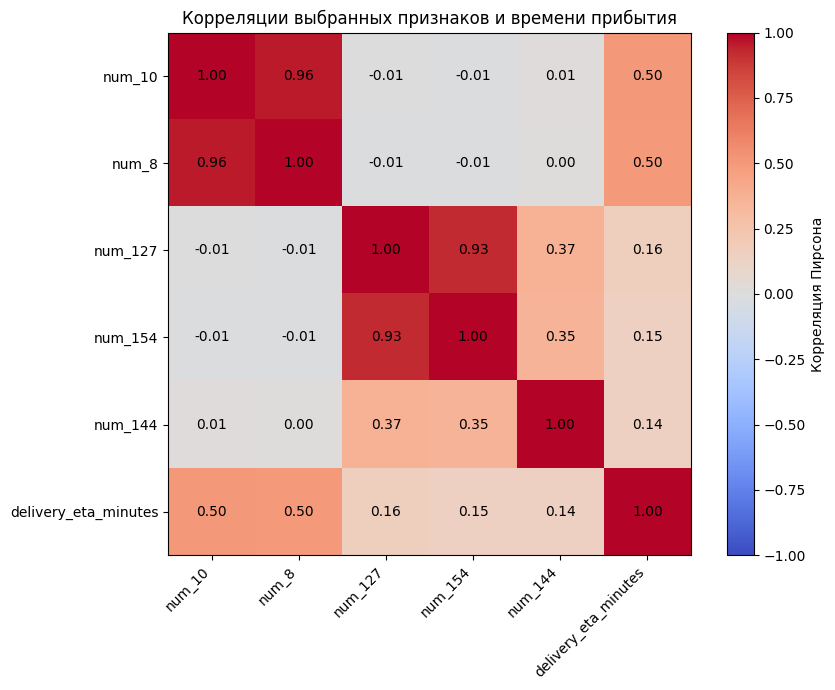

In [17]:
matrix_columns = important_num_cols + [target_col]
matrix = []
for first_column in matrix_columns:
    matrix_row = []
    for second_column in matrix_columns:
        correlation = df.stat.corr(first_column, second_column)
        matrix_row.append(correlation)
    matrix.append(matrix_row)

fig, ax = plt.subplots(figsize=(9, 7))
image_plot = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
positions = list(range(len(matrix_columns)))
ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(matrix_columns, rotation=45, ha="right")
ax.set_yticklabels(matrix_columns)

for i in range(len(matrix_columns)):
    for j in range(len(matrix_columns)):
        label = "—"
        if math.isfinite(matrix[i][j]):
            label = f"{matrix[i][j]:.2f}"
        ax.text(j, i, label, ha="center", va="center")
fig.colorbar(image_plot, ax=ax, label="Корреляция Пирсона")
ax.set_title("Корреляции выбранных признаков и времени прибытия")
plt.tight_layout()
plt.show()


### 14. Результат очистки и сохранение
Покажем потери строк и столбцов. Исходная таблица первой части сохраняется. В новую таблицу записываем очищенные наблюдения после IQR-фильтрации и устранения пропусков.


In [18]:
final_rows = df.count()
print(f"Исходных строк: {initial_rows}")
print(f"Отрицательных длительностей удалено: {negative_count}")
print(f"Строк без цели удалено: {missing_target_count}")
print(f"Строк без времени после проверки цели удалено: {missing_time_count}")
print(f"Строк за границами IQR удалено: {outlier_count}")
print(f"Итоговых строк: {final_rows}")
print(f"Числовых столбцов удалено по доле пропусков: {len(dropped_num_cols)}")
print(f"Полностью пустых бинарных и категориальных столбцов удалено: {len(dropped_discrete_cols)}")
print(f"Итоговых столбцов: {len(df.columns)}")
print(f"Пропусков после заполнения: {remaining_missing}")

# Модели не обучаем: сохраняем только результат разведочного анализа и очистки.
df.writeTo(processed_table).using("iceberg").createOrReplace()
saved_df = spark.table(processed_table)
print(f"Строк в сохранённой таблице: {saved_df.count()}")
saved_df.printSchema()


Исходных строк: 17044043
Отрицательных длительностей удалено: 0
Строк без цели удалено: 0
Строк без времени после проверки цели удалено: 0
Строк за границами IQR удалено: 1023764
Итоговых строк: 16020279
Числовых столбцов удалено по доле пропусков: 52
Полностью пустых бинарных и категориальных столбцов удалено: 0
Итоговых столбцов: 175
Пропусков после заполнения: 0


26/10/28 20:54:50 WARN HadoopTableOperations: Error reading version hint file hdfs:/user/user0/warehouse/delivery_eta_database/sobd_lab1_delivery_eta_processed/metadata/version-hint.text
java.io.FileNotFoundException: File does not exist: /user/user0/warehouse/delivery_eta_database/sobd_lab1_delivery_eta_processed/metadata/version-hint.text
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:87)
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:77)
	at org.apache.hadoop.hdfs.server.namenode.FSDirStatAndListingOp.getBlockLocations(FSDirStatAndListingOp.java:159)
	at org.apache.hadoop.hdfs.server.namenode.FSNamesystem.getBlockLocations(FSNamesystem.java:2198)
	at org.apache.hadoop.hdfs.server.namenode.NameNodeRpcServer.getBlockLocations(NameNodeRpcServer.java:795)
	at org.apache.hadoop.hdfs.protocolPB.ClientNamenodeProtocolServerSideTranslatorPB.getBlockLocations(ClientNamenodeProtocolServerSideTranslatorPB.java:468)
	at org.apache.hadoop

Строк в сохранённой таблице: 16020279
root
 |-- num_0: float (nullable = true)
 |-- num_1: float (nullable = true)
 |-- num_2: float (nullable = true)
 |-- num_3: float (nullable = true)
 |-- num_4: float (nullable = true)
 |-- num_5: float (nullable = true)
 |-- num_6: float (nullable = true)
 |-- num_7: float (nullable = true)
 |-- num_8: float (nullable = true)
 |-- num_9: float (nullable = true)
 |-- num_10: float (nullable = true)
 |-- num_11: float (nullable = true)
 |-- num_12: float (nullable = true)
 |-- num_13: float (nullable = true)
 |-- num_14: float (nullable = true)
 |-- num_15: float (nullable = true)
 |-- num_16: float (nullable = true)
 |-- num_17: float (nullable = true)
 |-- num_18: float (nullable = true)
 |-- num_19: float (nullable = true)
 |-- num_20: float (nullable = true)
 |-- num_21: float (nullable = true)
 |-- num_22: float (nullable = true)
 |-- num_23: float (nullable = true)
 |-- num_24: float (nullable = true)
 |-- num_25: float (nullable = true)
 |-- 

### Проверка объёма итогового датасета

Требование к результату: размер сохранённых файлов данных должен быть **больше 1 ГБ**. Для проверки используем более строгую границу **1 ГиБ = 1024³ = 1 073 741 824 байта**, которая превышает десятичный гигабайт (1 000 000 000 байт).

Удаление строк и столбцов, а также заполнение пропусков меняют размер Parquet. Он зависит и от сжатия, поэтому число строк, число признаков или размер исходного файла не доказывают выполнение требования.

После записи получим размеры текущих файлов через служебную таблицу Iceberg `files`. Поле `file_size_in_bytes` содержит размер файла в байтах; `content = 0` обозначает файл данных. Суммируем только файлы текущего состояния таблицы, без старых версий, служебных метаданных и умножения на число реплик HDFS. Такой подсчёт не завышает размер результата за счёт хранения лишних копий.

Источник полей: [документация Apache Iceberg](https://github.com/apache/iceberg/blob/main/docs/docs/spark-queries.md#files).

Проверка выполняется по результату **полного запуска на сервере**. Если объём окажется не больше порога, требование ещё не выполнено: необходимо пересмотреть выбранные правила удаления с учётом качества данных и повторить измерение. Искусственно дописывать повторы или считать старые файлы частью очищенного датасета нельзя.


In [19]:
# Читаем сведения о текущих файлах сохранённой таблицы.
# Это метаданные размеров, а не повторная загрузка миллионов заказов.
file_metadata = spark.table(processed_table + ".files")
data_files = file_metadata.filter(F.col("content") == 0)

# Складываем размеры всех текущих файлов данных.
size_row = data_files.select(F.sum("file_size_in_bytes")).first()
result_size_bytes = size_row[0]
if result_size_bytes is None:
    result_size_bytes = 0

# В одном ГиБ 1024 * 1024 * 1024 байта.
minimum_size_bytes = 1024 * 1024 * 1024
result_size_gib = result_size_bytes / minimum_size_bytes
print(f"Размер итоговых файлов данных: {result_size_bytes} байт ({result_size_gib:.3f} ГиБ)")

if result_size_bytes > minimum_size_bytes:
    print("Требование к объёму выполнено: итоговый датасет больше 1 ГиБ.")
else:
    print("Требование к объёму не выполнено: итоговый датасет не больше 1 ГиБ.")


Размер итоговых файлов данных: 8122831406 байт (7.565 ГиБ)
Требование к объёму выполнено: итоговый датасет больше 1 ГиБ.


### 15. Выводы по заданию

Выводы заполняем после выполнения на полном датасете:

1. Какие количественные, бинарные, категориальные и временные признаки представлены?
2. В каких столбцах были пропуски, какие удалены и какими значениями заполнены остальные?
3. Сколько найдено отрицательных длительностей и сколько наблюдений исключено по IQR? Как это изменило среднее, медиану, P95 и форму распределения времени прибытия?
4. Какие числовые признаки выбраны по абсолютной корреляции и как выглядят их распределения?
5. Какие связи наблюдаются между числовыми признаками? Какие различия видны между категориями, часами и датами?
6. Сколько строк и столбцов сохранилось, остались ли пропуски и превысил ли итоговый объём 1 ГиБ?

Ограничения: индивидуальные смыслы обезличенных признаков неизвестны; высокий коэффициент корреляции не означает причинную связь; правило IQR может исключать реальные долгие доставки. Частоты и выводы относятся к очищенному набору, а не автоматически ко всем заказам сервиса.


In [20]:
spark.stop()  # Освобождаем ресурсы приложения на кластере.
